# 03 · İlk CNN Modeli

**Amaç:** Kendi tasarladığımız küçük CNN'i eğitmek ve doğrulama kümesinde ne kadar iyi olduğunu görmek.

| Bölüm | Ne yapılıyor? |
|---|---|
| 1. Kurulum ve ayarlar | GPU kontrolü, eğitim ayarları |
| 2. Veriyi yükleme | İşlenmiş veri ve bölme Drive'dan okunur |
| 3. DataLoader | Veriyi modele gruplar halinde vermek |
| 4. Model | CNN'in katmanları ve parametre sayısı |
| 5. Kayıp fonksiyonu ve optimizer | Hatanın ölçülmesi, ağırlıkların güncellenmesi |
| 6. Eğitim | Eğitim döngüsü ve erken durdurma |
| 7. Öğrenme eğrileri | Model öğreniyor mu, ezberliyor mu? |
| 8. Doğrulama sonuçları | Karar eşiği, ölçütler, karmaşıklık matrisi |
| 9. Kaydetme | Model ve sonuçlar Drive'a |

**Çalışma zamanı:** Çalışma zamanı → Çalışma zamanı türünü değiştir → **T4 GPU**. Süre yaklaşık 15–25 dakika.

Test kümesi bu defterde kullanılmıyor.

In [1]:
# --- Kurulum: hem Google Colab'da hem kendi bilgisayarında çalışır ---
import os, sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")                     # işlenmiş veri Drive'da saklanır
    REPO = Path("/content/tornado-cnn")
    if not REPO.exists():
        try:                                          # repo private ise: Colab Secrets'taki token
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:                             # repo public ise token gerekmez
            token = ""
        !git clone -q https://{token}github.com/baevv/tornado-cnn.git {REPO}
    else:
        !git -C {REPO} pull -q
    %pip install -q h5netcdf h5py
    os.chdir(REPO)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(REPO))
# src/ klasöründen daha önce yüklenmiş kodu bellekten sil: git pull ile gelen yeni kod
# bir sonraki import'ta kullanılsın (oturumu yeniden başlatmaya gerek kalmasın).
for _m in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]

print("Colab" if IN_COLAB else "Yerel", "| repo:", REPO)

Mounted at /content/drive
Colab | repo: /content/tornado-cnn


## 1. Kurulum ve ayarlar

Eğitim ayarları `configs/train.json` dosyasından okunuyor.

| Ayar | Değer | Ne yapar? |
|---|---|---|
| `batch_size` | 64 | Her adımda modele verilen görüntü sayısı |
| `optimizer` | adam | Ağırlıkları güncelleyen yöntem |
| `lr` | 0,001 | Öğrenme oranı: her güncellemedeki adım büyüklüğü |
| `weight_decay` | 0 | L2 cezası (ilk modelde kapalı) |
| `epochs` | 20 | En fazla tur sayısı |
| `patience` | 4 | Doğrulama PR-AUC'si 4 tur iyileşmezse eğitim durur |
| `dropout` | 0,3 | Eğitimde nöronların %30'u rastgele kapatılır |
| `weighting` | pos_weight | Sınıf dengesizliği için kayıp ağırlığı |
| `monitor` | pr_auc | En iyi tur, erken durdurma ve lr planlaması doğrulama PR-AUC'sine göre (ana ölçüt, dengesiz veri) |
| `augment` | false | Temel modelde augmentation yok (karar A1); `05_cnn_aug` deneyinde açılır |
| `label_smoothing` | 0 | Temel modelde yok; `05_cnn_ls` deneyinde pozitif etiketler 1 → 0,9 (karar O2) |
| `seed` | 42 | Sonuçların tekrarlanabilir olması için sabit başlangıç |

In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from src.helper import paths, train
from src.helper import model as cnn

cfg_data = paths.load_config()
with open(REPO / "configs" / "train.json") as f:
    cfg = json.load(f)

device = train.get_device()
if device.type == "cuda":
    print("cihaz: GPU |", torch.cuda.get_device_name(0))
else:
    print("UYARI: GPU yok, eğitim çok yavaş olur. Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU")
train.set_seed(cfg["seed"])
cfg

cihaz: GPU | Tesla T4


{'batch_size': 64,
 'optimizer': 'adam',
 'lr': 0.001,
 'weight_decay': 0.0,
 'epochs': 20,
 'patience': 4,
 'dropout': 0.3,
 'weighting': 'pos_weight',
 'monitor': 'pr_auc',
 'augment': False,
 'label_smoothing': 0.0,
 'seed': 42,
 'num_workers': 2}

## 2. Veriyi yükleme

* İşlenmiş `.npz` dosyaları Drive'dan Colab'ın diskine kopyalanır ve belleğe `uint8` olarak alınır. [-1, 1] aralığına çevirme her grup için ayrı yapılır; hepsini birden çevirmek belleğe sığmazdı.
* Eğitim ve doğrulama kümeleri `splits.csv`'den okunur. Test kümesi yüklenmez.

`HIZLI_DENEME = True` yapılırsa sadece 2017 kullanılır (kodu denemek için; sonuçlar gerçek sonuç değildir).

In [3]:
HIZLI_DENEME = False      # True: sadece 2017 ile hızlı deneme

years = [2017] if HIZLI_DENEME else cfg_data["years"]
splits = train.load_splits(paths.data_dir())
local_dir = Path("/content/data_local") if IN_COLAB else None
data, variables = train.load_data(paths.processed_dir(), splits, years, which=("train", "val"), local_dir=local_dir)

summary = pd.DataFrame({
    s: {"örnek": len(d["y"]), "hortum": int(d["y"].sum()), "hortum_%": round(100 * d["y"].mean(), 1),
        "bellek (GB)": round(d["X"].nbytes / 1e9, 2)}
    for s, d in data.items()
}).T
print("yıllar:", years, "| kanallar:", variables, "| bir örnek:", data["train"]["X"].shape[1:])
summary

yıllar: [2015, 2017, 2019] | kanallar: ['DBZ', 'VEL', 'WIDTH'] | bir örnek: (3, 120, 240)


,örnek,hortum,hortum_%,bellek (GB)
train,48703.0,3786.0,7.8,4.21
val,8040.0,690.0,8.6,0.69


## 3. DataLoader

DataLoader veriyi modele 64'lük gruplar (batch) halinde verir; ağırlıklar her gruptan sonra güncellenir.

* Eğitim verisi her turda karıştırılır, doğrulama verisi karıştırılmaz.
* Her grup GPU'da [-1, 1] aralığına çevrilir ve boş pikseller doldurulur (DBZ → −1, VEL → 0, WIDTH → −1).

In [4]:
w_train, pos_weight = train.class_weights(data["train"]["meta"], cfg["weighting"])
train_loader, val_loader = train.make_loaders(data, cfg, w_train)

xb, yb, wb, rb = next(iter(train_loader))   # rb: ilk mesafe hücresinin uzaklığı, km (yalnız CoordConv kullanır)
x = train.decode_batch(xb.to(device), variables)
print(f"bir grup: {list(x.shape)} | değerler [{x.min():.2f}, {x.max():.2f}] | bu grupta {int(yb.sum())} hortum")
print(f"eğitimde {len(train_loader)} grup, doğrulamada {len(val_loader)} grup")

bir grup: [64, 3, 120, 240] | değerler [-1.00, 1.00] | bu grupta 2 hortum
eğitimde 761 grup, doğrulamada 63 grup


## 4. Model

**Katmanlar ve görevleri** (kod: `src/helper/model.py`):

| Katman | Ne yapar? |
|---|---|
| **Evrişim (Conv 3×3)** | Filtre görüntünün üzerinde kayarak şekilleri yakalar (özellik haritası). |
| **ReLU** | Negatif değerleri sıfırlar; ağa doğrusal olmayan davranış kazandırır. |
| **Max havuzlama (2×2)** | Görüntüyü yarıya küçültür, her bölgenin en büyük değerini tutar. |
| **Global max havuzlama** | Her özellik haritasından en büyük değeri alır; hortumun görüntüdeki yeri fark etmez. |
| **Tam bağlı (Dense)** | Çıkarılan özelliklerden kararı verir. |
| **Dropout** | Eğitimde nöronların bir kısmını rastgele kapatır (tahminde kapalı). |

Son katmanda sigmoid yok: Çıktı bir logit; sigmoid kayıp fonksiyonunun içinde uygulanıyor.

**Neden bu mimari?** Görüntü verisi olduğu için CNN; küçük tutuldu çünkü ~49 bin eğitim görüntüsü için milyonlarca parametreli bir model kolayca ezberler. Filtre sayısı derinleştikçe artıyor (16 → 128): ilk katmanlar basit geçişleri, son katmanlar bunların birleşimini (hız çifti gibi) öğreniyor.

Aşağıdaki tabloda her katmanın çıktı boyutu, eğitilebilir parametre sayısı ve bu parametrelerin hesaplama formülü yer alıyor.

In [5]:
net = cnn.TornadoCNN(in_channels=len(variables), dropout=cfg["dropout"]).to(device)
table = cnn.layer_table(net, input_shape=tuple(data["train"]["X"].shape[1:]))
print(f"toplam eğitilebilir parametre: {cnn.count_params(net):,}")
table

toplam eğitilebilir parametre: 105,761


,katman,çıktı boyutu,parametre,formül
0,Conv2d,16 × 120 × 240,448,(3·3·3 + 1) · 16
1,ReLU,16 × 120 × 240,0,
2,MaxPool2d,16 × 60 × 120,0,
3,Conv2d,32 × 60 × 120,4640,(3·3·16 + 1) · 32
4,ReLU,32 × 60 × 120,0,
5,MaxPool2d,32 × 30 × 60,0,
6,Conv2d,64 × 30 × 60,18496,(3·3·32 + 1) · 64
7,ReLU,64 × 30 × 60,0,
8,MaxPool2d,64 × 15 × 30,0,
9,Conv2d,128 × 15 × 30,73856,(3·3·64 + 1) · 128


## 5. Kayıp fonksiyonu ve optimizer

* **Kayıp: `BCEWithLogitsLoss`:** Sigmoid ve ikili çapraz entropi tek işlemde.
* **`pos_weight` = hortumsuz sayısı / hortum sayısı:** Hortumu kaçırmak bu oranda daha fazla cezalandırılır; model her şeye "hortum yok" demeye kaçmaz.
* **Optimizer:** Adam, öğrenme oranı 0,001.

In [6]:
n_pos = int(data["train"]["y"].sum())
n_neg = len(data["train"]["y"]) - n_pos
print(f"ağırlık türü: {cfg['weighting']}")
print(f"pos_weight = {n_neg:,} / {n_pos:,} = {pos_weight:.2f}")
print(f"optimizer: {cfg['optimizer']} | öğrenme oranı: {cfg['lr']}")

ağırlık türü: pos_weight
pos_weight = 44,917 / 3,786 = 11.86
optimizer: adam | öğrenme oranı: 0.001


## 6. Eğitim

Her grupta dört adım yapılır:

```
1. İleri yayılım:  model görüntülere bakar, tahmin üretir
2. Kayıp:          tahminler gerçek etiketlerle karşılaştırılır
3. Geri yayılım:   loss.backward()  → gradyanlar hesaplanır
4. Güncelleme:     optimizer.step() → ağırlıklar güncellenir
```

Her turun (epoch) sonunda doğrulama kümesinde kayıp, ROC-AUC ve PR-AUC hesaplanır.

* **Erken durdurma:** Doğrulama AUC'si 4 tur iyileşmezse eğitim durur ve en iyi turdaki ağırlıklara dönülür.
* **Kayıt:** Her tur Drive'a kaydedilir. Bağlantı koparsa bu hücreyi tekrar çalıştır; kaldığı turdan devam eder.
* ★ en iyi turu gösterir.

In [7]:
OUT = paths.models_dir("03_baseline_hizli" if HIZLI_DENEME else "03_baseline")
print("kayıt klasörü:", OUT)
history = train.fit(net, train_loader, val_loader, cfg, variables, OUT, pos_weight, device)

kayıt klasörü: /content/drive/MyDrive/tornado-cnn/models/03_baseline
Klasörde farklı ayarlarla eğitilmiş bir kayıt var; baştan başlanıyor.
tur  1 | eğitim kaybı 1.0825 | doğrulama kaybı 0.9022 | AUC 0.8597 | PR-AUC 0.4774 | 27 sn  ★ en iyi
tur  2 | eğitim kaybı 0.8617 | doğrulama kaybı 1.0604 | AUC 0.8507 | PR-AUC 0.4634 | 27 sn
tur  3 | eğitim kaybı 0.7919 | doğrulama kaybı 0.8433 | AUC 0.8781 | PR-AUC 0.5600 | 29 sn  ★ en iyi
tur  4 | eğitim kaybı 0.7383 | doğrulama kaybı 0.8199 | AUC 0.8901 | PR-AUC 0.5724 | 28 sn  ★ en iyi
tur  5 | eğitim kaybı 0.7059 | doğrulama kaybı 0.8546 | AUC 0.8823 | PR-AUC 0.5843 | 28 sn  ★ en iyi
tur  6 | eğitim kaybı 0.6768 | doğrulama kaybı 0.8948 | AUC 0.8769 | PR-AUC 0.5432 | 28 sn
tur  7 | eğitim kaybı 0.6425 | doğrulama kaybı 0.8610 | AUC 0.8804 | PR-AUC 0.5469 | 28 sn
tur  8 | eğitim kaybı 0.6077 | doğrulama kaybı 0.9362 | AUC 0.8814 | PR-AUC 0.5623 | 28 sn
tur  9 | eğitim kaybı 0.5601 | doğrulama kaybı 1.1202 | AUC 0.8480 | PR-AUC 0.5130 | 28 sn  →

## 7. Öğrenme eğrileri

* **Sol, kayıp:** Eğitim kaybı düşerken doğrulama kaybı yükselmeye başlarsa model ezberlemeye (aşırı öğrenme) başlamış demektir.
* **Sağ, doğrulama AUC ve PR-AUC:** Kesikli çizgi en iyi tur. Rastgele bir modelin PR-AUC'si hortum oranı kadardır (~0,08).

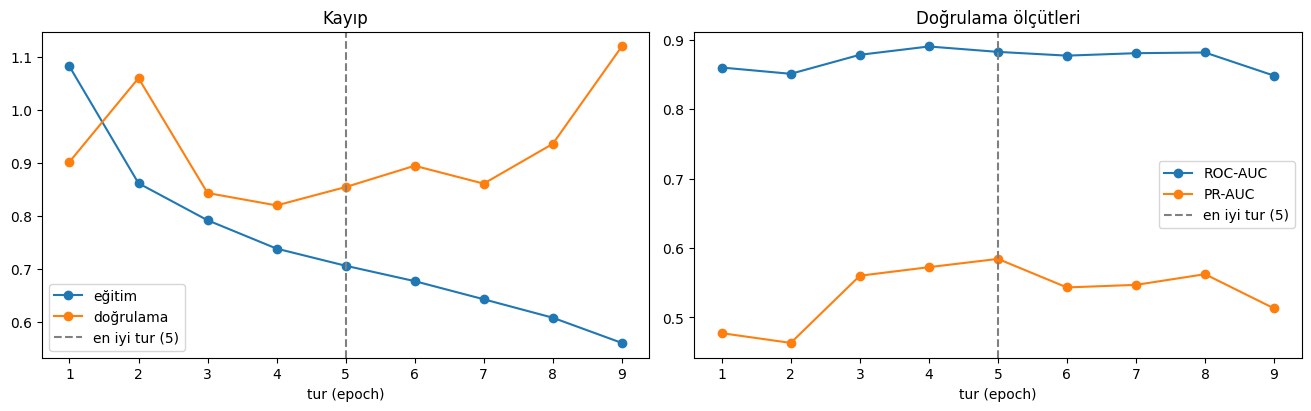

,tur,eğitim kaybı,doğrulama kaybı,doğrulama AUC,doğrulama PR-AUC,süre (sn),lr
0,1,1.0825,0.9022,0.8597,0.4774,26.8968,0.001
1,2,0.8617,1.0604,0.8507,0.4634,27.2047,0.001
2,3,0.7919,0.8433,0.8781,0.5600,28.8623,0.001
3,4,0.7383,0.8199,0.8901,0.5724,28.4046,0.001
4,5,0.7059,0.8546,0.8823,0.5843,27.8681,0.001
5,6,0.6768,0.8948,0.8769,0.5432,27.9856,0.001
6,7,0.6425,0.8610,0.8804,0.5469,28.0763,0.001
7,8,0.6077,0.9362,0.8814,0.5623,28.0031,0.001
8,9,0.5601,1.1202,0.8480,0.5130,28.2326,0.001


In [8]:
best = train.best_epoch(history, cfg)   # izlenen ölçüt: doğrulama PR-AUC (karar O1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
axes[0].plot(history["tur"], history["eğitim kaybı"], "o-", label="eğitim")
axes[0].plot(history["tur"], history["doğrulama kaybı"], "o-", label="doğrulama")
axes[0].set_title("Kayıp")
axes[1].plot(history["tur"], history["doğrulama AUC"], "o-", label="ROC-AUC")
axes[1].plot(history["tur"], history["doğrulama PR-AUC"], "o-", label="PR-AUC")
axes[1].set_title("Doğrulama ölçütleri")
for ax in axes:
    ax.axvline(best, color="gray", ls="--", label=f"en iyi tur ({best})")
    ax.set_xlabel("tur (epoch)")
    ax.legend()
plt.show()
history.round(4)

## 8. Doğrulama sonuçları

**Karar eşiği:** Doğrulama kümesinde F1'i en yüksek yapan skor değeri seçilir. Test kümesinde de aynı eşik kullanılacak.

| Ölçüt | Soru |
|---|---|
| Doğruluk | Tahminlerin yüzde kaçı doğru? (dengesiz veride yanıltıcı) |
| Recall (yakalama) | Gerçek hortumların yüzde kaçı bulundu? |
| Precision (isabet) | "Hortum" denenlerin yüzde kaçı gerçekten hortum? |
| F1 | Recall ile precision'ın dengesi |
| ROC-AUC, PR-AUC | Eşikten bağımsız ayırt etme gücü |

Karşılaştırma için: her örneğe "hortum yok" diyen model.

In [9]:
y_val = data["val"]["y"]
p_val, _ = train.predict(net, val_loader, variables, device, pos_weight)
threshold = train.choose_threshold(y_val, p_val)
CHOSEN = f"Bizim CNN (seçilen eşik {threshold:.3f})"

rows = {
    "Her şeye 'hortum yok'": train.metrics(y_val, np.zeros_like(p_val), 0.5),
    "Bizim CNN (eşik 0.5)": train.metrics(y_val, p_val, 0.5),
    CHOSEN: train.metrics(y_val, p_val, threshold),
}
results_val = pd.DataFrame(rows).T
print(f"seçilen eşik: {threshold:.3f}")
results_val.round(3)

seçilen eşik: 0.731


,doğruluk,recall (yakalama),precision (isabet),F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
Her şeye 'hortum yok',0.914,0.000,0.000,0.000,0.500,0.086,0.0,0.0,690.0,7350.0
Bizim CNN (eşik 0.5),0.876,0.729,0.384,0.503,0.882,0.584,503.0,808.0,187.0,6542.0
Bizim CNN (seçilen eşik 0.731),0.926,0.574,0.567,0.570,0.882,0.584,396.0,303.0,294.0,7047.0


**Karmaşıklık matrisi** (seçilen eşikle, doğrulama kümesi):

* **Sol üst:** Doğru "hortum yok" · **Sağ üst:** Yanlış alarm
* **Sol alt:** Kaçırılan hortum · **Sağ alt:** Yakalanan hortum

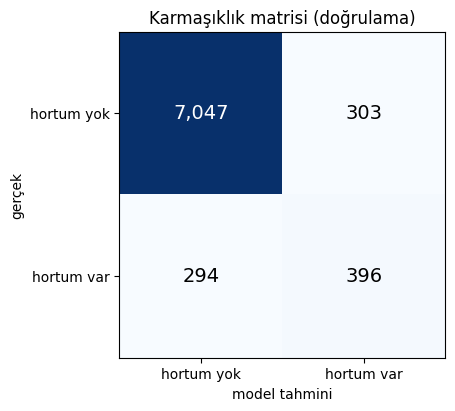

In [10]:
m = rows[CHOSEN]
cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
fig, ax = plt.subplots(figsize=(4.5, 4), layout="constrained")
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["hortum yok", "hortum var"])
ax.set_yticks([0, 1], ["hortum yok", "hortum var"])
ax.set_xlabel("model tahmini")
ax.set_ylabel("gerçek")
ax.set_title("Karmaşıklık matrisi (doğrulama)")
plt.show()

## 9. Kaydetme

Drive'a (`tornado-cnn/models/03_baseline/`) kaydedilenler:

* `best.pt`: en iyi turdaki model ağırlıkları
* `last.pt`: son durum (kaldığı yerden devam etmek için)
* `history.json`: tur tur kayıp ve AUC değerleri
* `results.json`: ayarlar, seçilen eşik, doğrulama sonuçları

In [11]:
train.save_results(
    OUT, config=cfg, years=years, variables=variables, pos_weight=pos_weight,
    best_epoch=best, threshold=threshold,
    validation=results_val.loc[CHOSEN].to_dict(),
)
for f in sorted(OUT.iterdir()):
    print(f"{f.name:15s} {f.stat().st_size / 1e6:6.2f} MB")

best.pt           0.43 MB
history.json      0.00 MB
last.pt           1.28 MB
results.json      0.00 MB
